### Модель Эрдеша - Реньи. Случайные графы

In [25]:
#!pip install networkx

In [26]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import poisson
import matplotlib as mpl
import pandas as pd

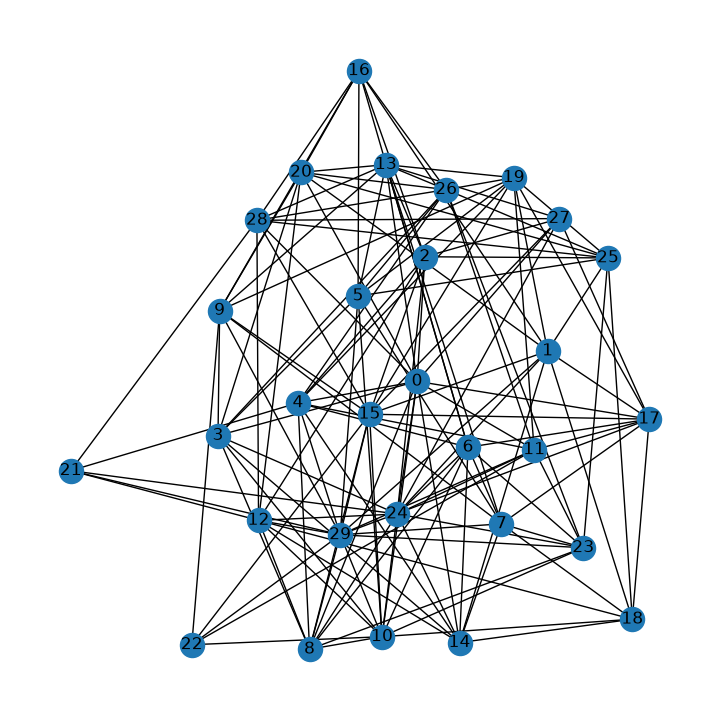

In [27]:
N = 30
P = 0.3
G = nx.erdos_renyi_graph(N, P, seed=42)
plt.figure(figsize=(7,7))
pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels = True)

Nodes  30 Edges:  143 Avg Degree:  9.533333333333333


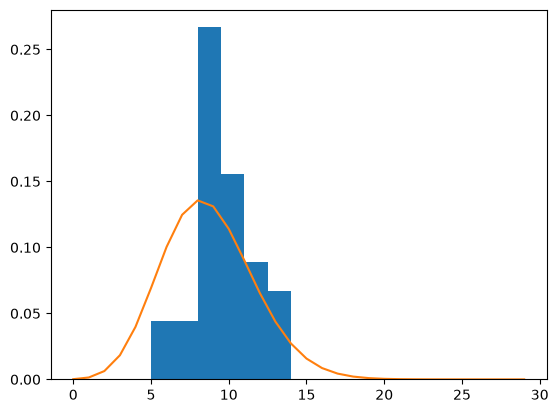

In [28]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
avg_degree = sum(dict(G.degree()).values()) / num_nodes if num_nodes > 0 else 0
print("Nodes ", num_nodes, "Edges: ", num_edges, "Avg Degree: ", avg_degree)
degrees = [d for n, d in G.degree]
plt.hist(degrees, bins = round(np.sqrt(N) + 1), density = True)
dist = poisson ((N - 1) * P)
I = np.array(range(N))
plt.plot(I, dist.pmf(I))

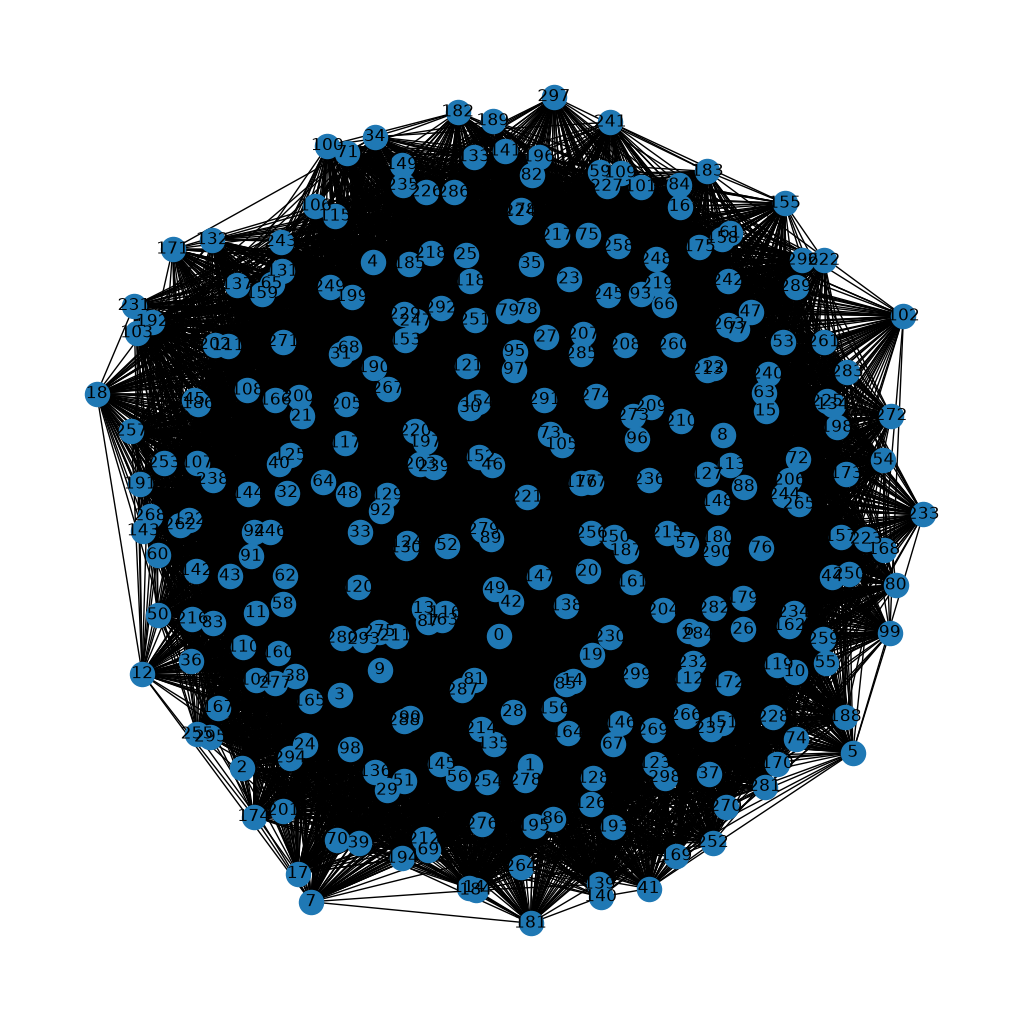

In [29]:
N = 300
P = 0.3
G = nx.erdos_renyi_graph(N, P, seed=42)
plt.figure(figsize=(10, 10))
pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels = True)

Nodes  300 Edges:  13369 Avg Degree:  89.12666666666667


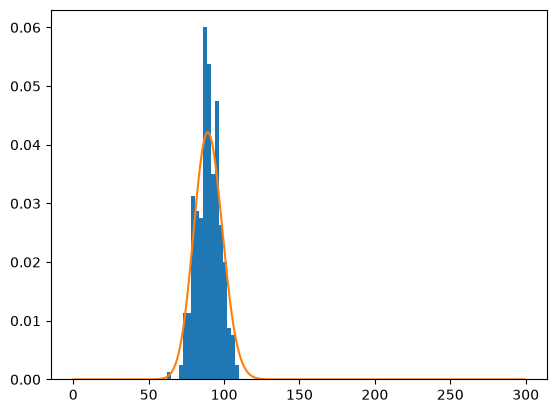

In [30]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
avg_degree = sum(dict(G.degree()).values()) / num_nodes if num_nodes > 0 else 0
print("Nodes ", num_nodes, "Edges: ", num_edges, "Avg Degree: ", avg_degree)
degrees = [d for n, d in G.degree]
plt.hist(degrees, bins = round(np.sqrt(N) + 1), density = True)
from scipy.stats import poisson
dist = poisson ((N - 1) * P)
I = np.array(range(N))
plt.plot(I, dist.pmf(I))

- Расстояние d
- Диаметр
- Центр

## Модель барабаши - Альберт (модель предпочтительного соединения). Случайный графы

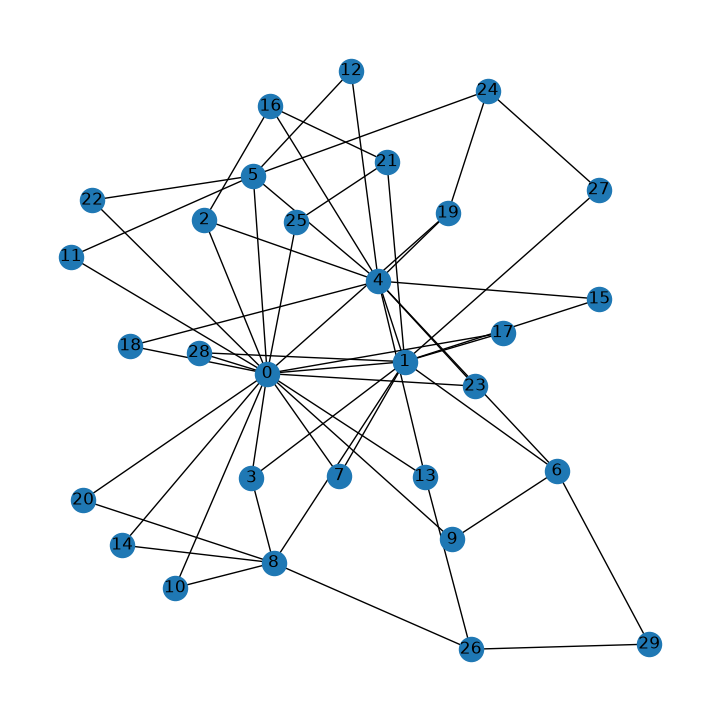

In [31]:
N = 30
m0 = 2
G = nx.barabasi_albert_graph(N, m0, seed=42)
plt.figure(figsize=(7, 7))
pos = nx.spring_layout(G, seed = 42)
nx.draw(G, pos, with_labels=True)

Nodes  30 Edges:  56 Avg Degree:  3.7333333333333334


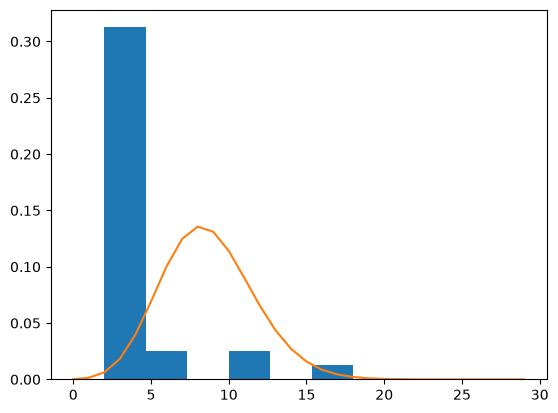

In [32]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
avg_degree = sum(dict(G.degree()).values()) / num_nodes if num_nodes > 0 else 0
print("Nodes ", num_nodes, "Edges: ", num_edges, "Avg Degree: ", avg_degree)
degrees = [d for n, d in G.degree]
plt.hist(degrees, bins = round(np.sqrt(N) + 1), density = True)
from scipy.stats import poisson
dist = poisson ((N - 1) * P)
I = np.array(range(N))
plt.plot(I, dist.pmf(I))

Nodes  30 Edges:  56 Avg Degree:  3.7333333333333334


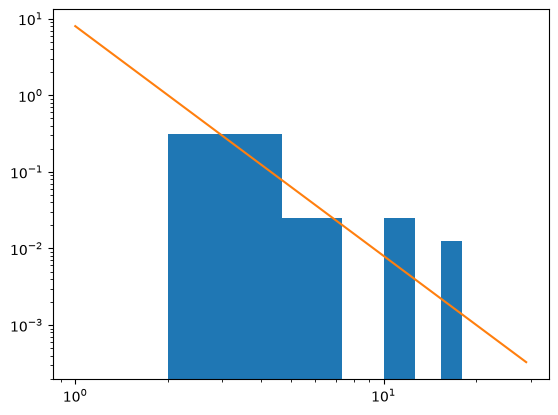

In [33]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
avg_degree = sum(dict(G.degree()).values()) / num_nodes if num_nodes > 0 else 0
print("Nodes ", num_nodes, "Edges: ", num_edges, "Avg Degree: ", avg_degree)
degrees = [d for n, d in G.degree]
plt.hist(degrees, bins = round(np.sqrt(N) + 1), density = True)
dist = poisson ((N - 1) * P)
I = np.array(range(1, N)).astype(float)
plt.plot(I, 2 * (m0**2)*(I**(-3)))
plt.xscale('log')
plt.yscale('log')

### Модель Уоттса-Строгаца(модель тесного мира). Случайные графы

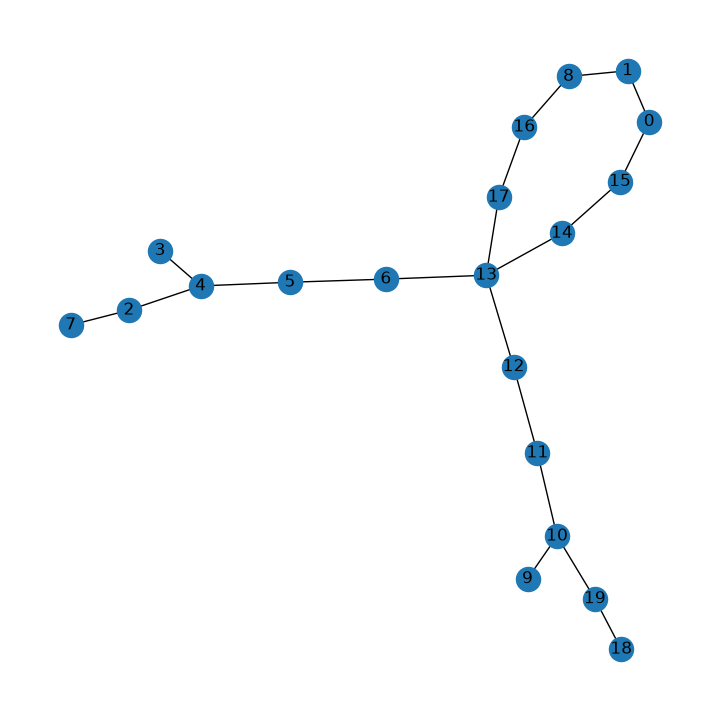

In [34]:
N = 20
G = nx.watts_strogatz_graph(N, m0, P, seed=42)
plt.figure(figsize=(7, 7))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True)

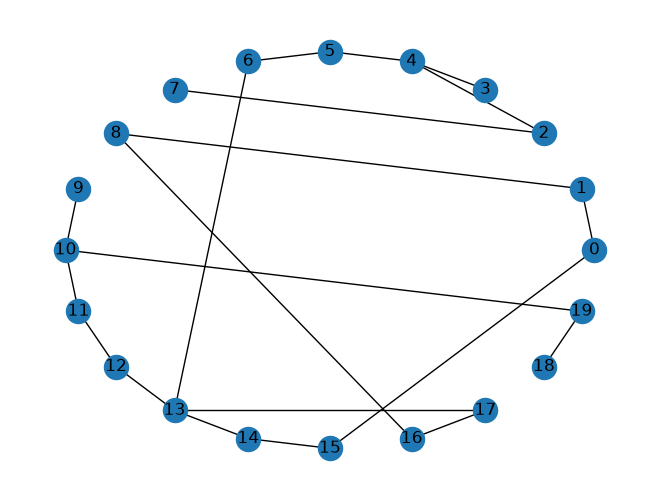

In [35]:
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels = True)

## Алгоритм Камада-Кавай для отображения графа

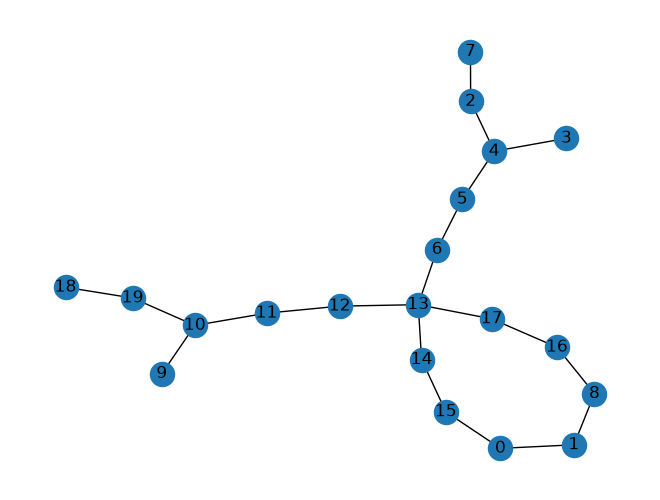

In [36]:
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, with_labels=True)

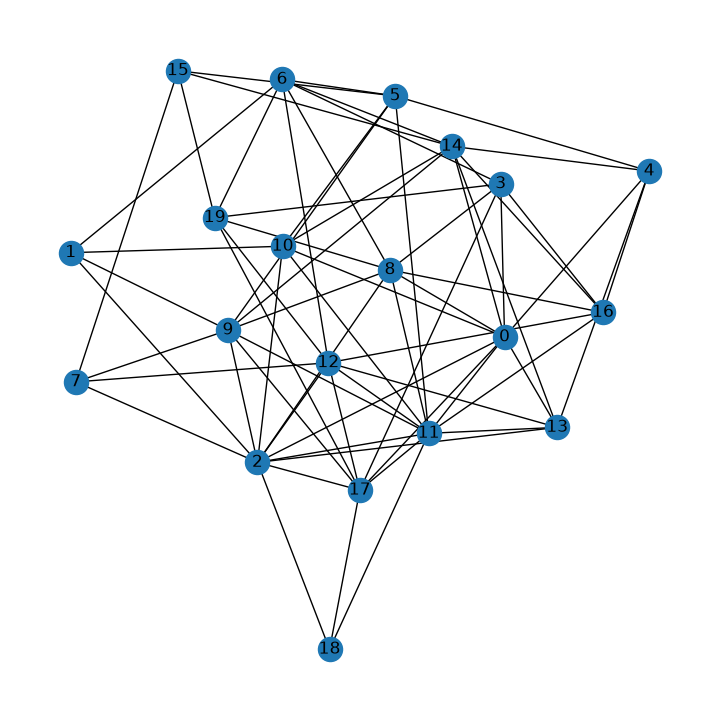

In [37]:
N = 20
P = 0.3
G = nx.erdos_renyi_graph(N, P, seed=42)
plt.figure(figsize=(7,7))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, with_labels=True)

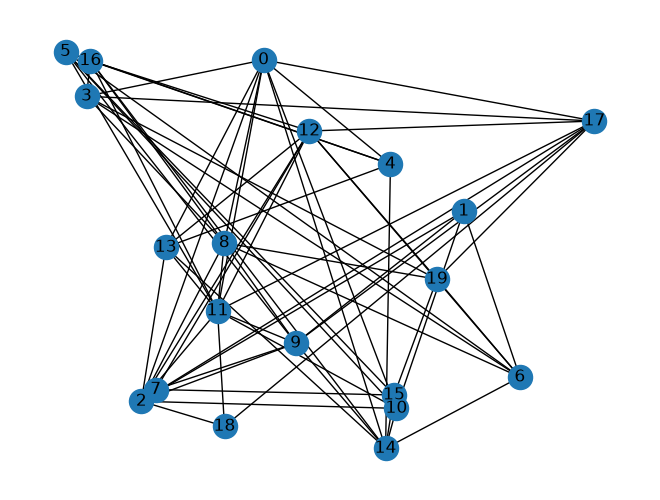

In [38]:
pos = nx.random_layout(G, seed=42)
nx.draw(G, pos, with_labels=True)

- Локальный коэффицент кластеризации - доля пар друзей узла, являющихся друзьями друг другу
- Глобальный(средний) коэффицент кластеризации - средний локальный коэффицент кластеризации по всем узлам графа
- Транзитивность - процент "открытых триад", являющихся треугольниками сети

Код:
- nx.clustering(G)
- nx.average_clustering(G)
- nx.Transitiviity(G)

(array([0., 0., 5., 0., 0.]),
 array([-0.5, -0.3, -0.1,  0.1,  0.3,  0.5]),
 <BarContainer object of 5 artists>)

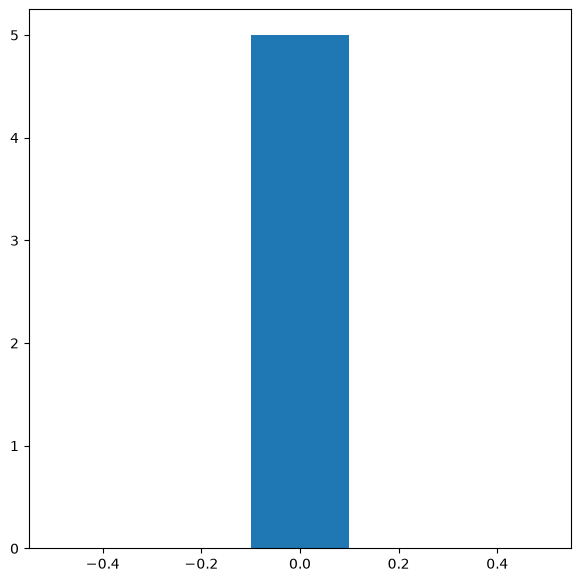

In [39]:
N = 20
G = nx.watts_strogatz_graph(N, m0, P, seed=42)
plt.figure(figsize=(7, 7))
pos = nx.spring_layout(G, seed=42)
local_clust = nx.clustering(G).values()
# nx.draw(G, pos, with_labels=True)
plt.hist(local_clust, bins = round(np.sqrt(N) + 1), density = True)

In [40]:
#!wget -c http://www-personal.umich.edu/~mejn/netdata/football.zip
# !unzip football.zip

{7, 8, 9, 10, 11, 12}


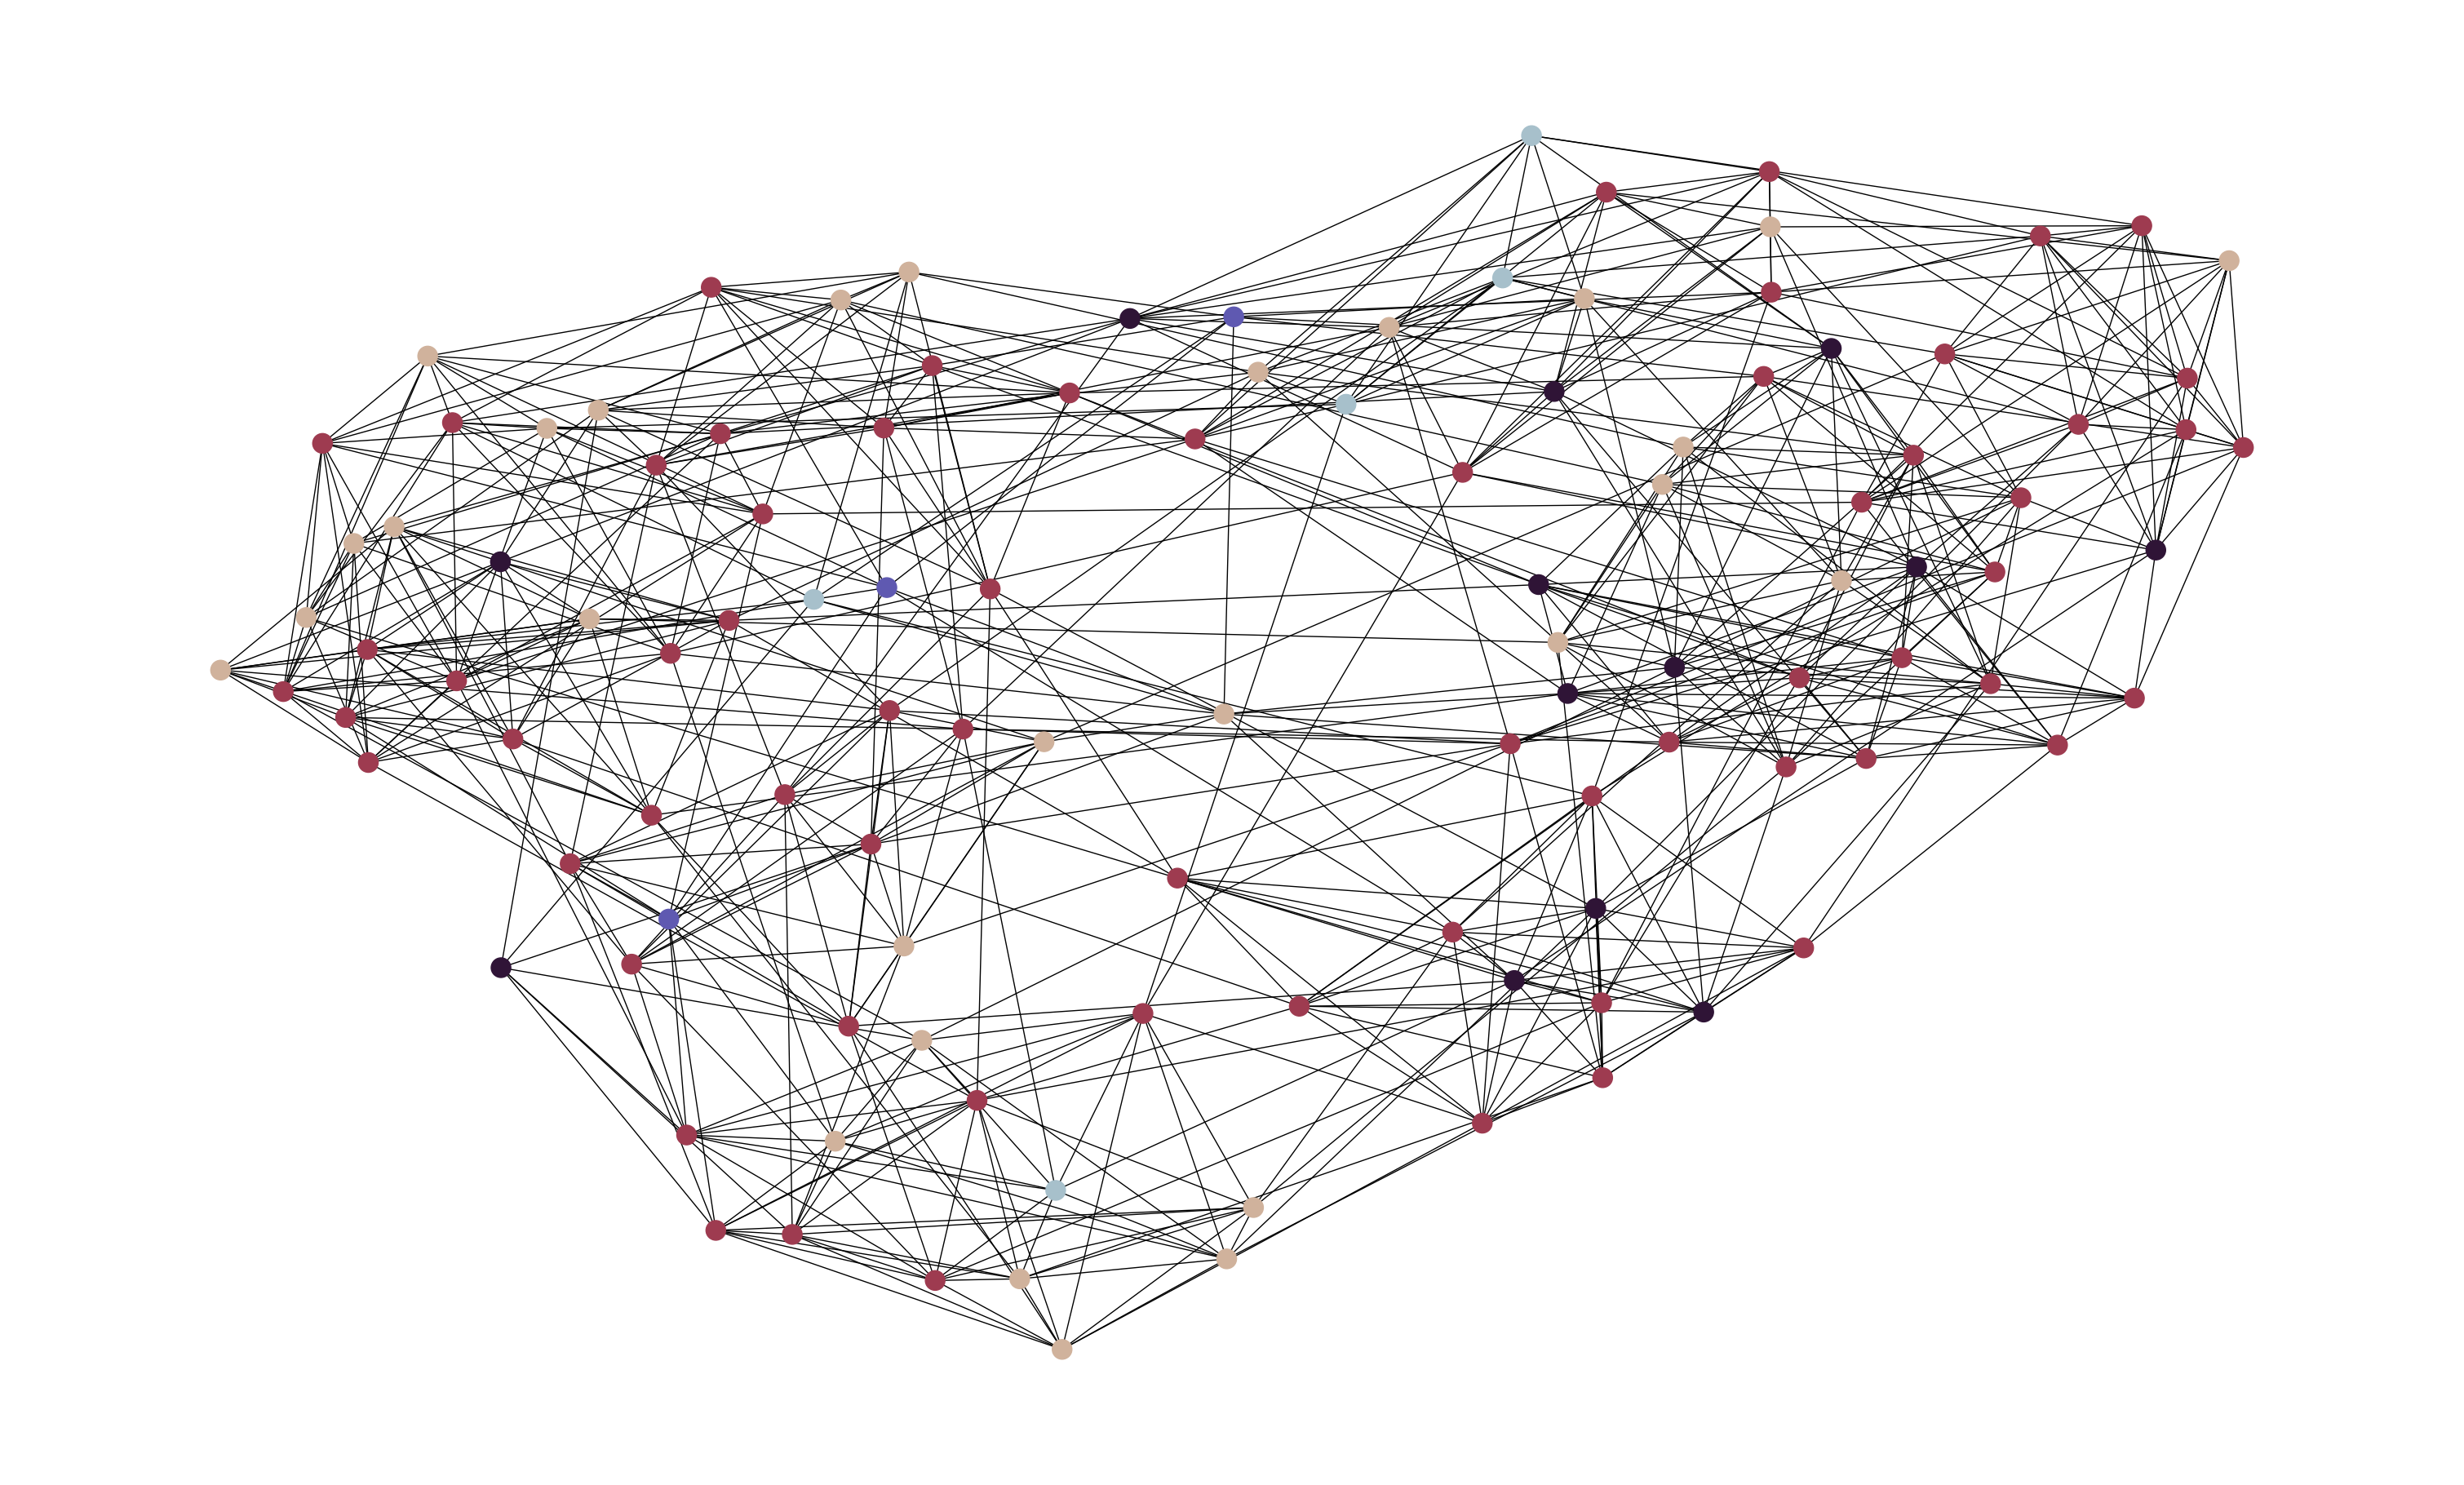

In [41]:
gml = open("football.gml").readlines()[1:]
G = nx.parse_gml(gml)
d = dict(G.degree)
print(set(d.values()))
low, *_, high = sorted(d.values())
norm = mpl.colors.Normalize(vmin=low, vmax=high, clip=True)
mapper = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.twilight_shifted)
options = {"node_size": 50, "linewidths": 0,"width": 0.1,}
plt.figure(figsize =(30, 18))
nx.draw(G, nodelist=d,  node_color=[mapper.to_rgba(i) for i in d.values()])
plt.show()

In [42]:
def GetGraphMetrics(graph):
    graph_degree = dict(graph.degree)
    print("Graph Summary:")
    print(f"Number of nodes : {len(graph.nodes)}")
    print(f"Number of edges : {len(graph.edges)}")
    print(f"Maximum degree : {np.max(list(graph_degree.values()))}")
    print(f"Minimum degree : {np.min(list(graph_degree.values()))}")
    print(f"Average degree : {np.mean(list(graph_degree.values()))}")
    print(f"Median degree : {np.median(list(graph_degree.values()))}")
    print("")
    print("Graph Connectivity")
    try:
        print(f"Connected Components : {nx.number_connected_components(graph)}")
    except:
        print(f"Strongly Connected Components : {nx.number_strongly_connected_components(graph)}")
        print(f"Weakly Connected Components : {nx.number_weakly_connected_components(graph)}")
    print("")
    print("Graph Distance")
    print(f"Average Distance : {nx.average_shortest_path_length(graph)}")
    print(f"Diameter : {nx.algorithms.distance_measures.diameter(graph)}")
    print("")
    print("Graph Clustering")
    print(f"Transitivity : {nx.transitivity(graph)}")
    print(f"Average Clustering Coefficient : {nx.average_clustering(graph)}")
    return None
GetGraphMetrics(G)

Graph Summary:
Number of nodes : 115
Number of edges : 613
Maximum degree : 12
Minimum degree : 7
Average degree : 10.660869565217391
Median degree : 11.0

Graph Connectivity
Connected Components : 1

Graph Distance
Average Distance : 2.5081617086193746
Diameter : 4

Graph Clustering
Transitivity : 0.4072398190045249
Average Clustering Coefficient : 0.403216011042098


## Центральность - это способ оценки важности узлов/рёбер в графе
Число Эрдёша или Бэйкона или Саббат

## Центральность близости - важные узлы располжены близко к друг другу

## Промежуточная центральность - важные узлы расположенны близко к другим узлам

## Центральность по собственному вектору - важные узлы соединены с центральными узлами

## PageRank - важные узлы - это узлы с большим количеством входящих ссылок из других важных узлов

## Хабы и авторитетные узлы (Hits) - важные узлы, имеющие входящие ребра от хороших хабов

In [43]:
def createBarChartForCentralityMeasures(sorted_centrality_teams, centrality_name):
    return pd.DataFrame(sorted_centrality_teams, columns=['Team', centrality_name])
metric_main_df = pd.DataFrame(index=list(d.keys()))
degree_centrality_df = createBarChartForCentralityMeasures(sorted(nx.degree_centrality(G).items(), key=lambda x:x[1], reverse=True), 'Degree Centrality')
closeness_centrality_df = createBarChartForCentralityMeasures(sorted(nx.closeness_centrality(G).items(), key=lambda x:x[1], reverse=True), 'Closeness Centrality')
betweenness_centrality_df = createBarChartForCentralityMeasures(sorted(nx.betweenness_centrality(G).items(), key=lambda x:x[1], reverse=True), 'Betweenness Centrality')
eigenvector_centrality_df = createBarChartForCentralityMeasures(sorted(nx.eigenvector_centrality(G).items(), key=lambda x:x[1], reverse=True), 'Eigenvector Centrality')
pagerank_df = createBarChartForCentralityMeasures(sorted(nx.pagerank(G).items(), key=lambda x:x[1], reverse=True), 'PageRank')
hub, auth = nx.hits(G)
hubs_df = createBarChartForCentralityMeasures(sorted(hub.items(), key=lambda x:x[1], reverse=True), 'Hubs')
authorities_df = createBarChartForCentralityMeasures(sorted(auth.items(), key=lambda x:x[1], reverse=True), 'Authorities')

for metric in [degree_centrality_df, closeness_centrality_df, betweenness_centrality_df, eigenvector_centrality_df, pagerank_df, hubs_df, authorities_df]:
    metric = metric.set_index('Team')
    metric_main_df = metric_main_df.join(metric)

metric_main_df

,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,PageRank,Hubs,Authorities
BrighamYoung,0.105263,0.423792,0.032490,0.106503,0.009588,0.010092,0.010092
FloridaState,0.105263,0.413043,0.017621,0.096385,0.009641,0.009132,0.009132
Iowa,0.105263,0.407143,0.013122,0.116262,0.009509,0.011017,0.011017
KansasState,0.105263,0.420664,0.023070,0.106250,0.009617,0.010069,0.010069
NewMexico,0.096491,0.402827,0.010664,0.101190,0.008887,0.009589,0.009589
...,...,...,...,...,...,...,...
TexasChristian,0.096491,0.413043,0.014370,0.114943,0.008777,0.010893,0.010893
California,0.096491,0.382550,0.007516,0.111198,0.008809,0.010538,0.010538
AlabamaBirmingham,0.087719,0.395833,0.011582,0.073015,0.008369,0.006918,0.006918
Arkansas,0.087719,0.377483,0.006498,0.070452,0.008369,0.006675,0.006675


In [44]:
metric_main_df.sort_values("Betweenness Centrality")[-1:]

,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,PageRank,Hubs,Authorities
NotreDame,0.096491,0.422222,0.033533,0.100915,0.008864,0.009563,0.009563


In [45]:
metric_main_df.sort_values("Degree Centrality")[-1:]

,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,PageRank,Hubs,Authorities
BrighamYoung,0.105263,0.423792,0.03249,0.106503,0.009588,0.010092,0.010092


In [46]:
metric_main_df.sort_values("Degree Centrality")[:1]

,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,PageRank,Hubs,Authorities
Connecticut,0.061404,0.37013,0.00779,0.048312,0.006269,0.004577,0.004577


### Плотность матрицы - l/N**2 или k / (N-1) k - степень верины